In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib


In [ ]:
import pandas as pd
import numpy as np
import joblib

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
import pandas as pd

# Correct training dataset URL
train_url = (
    "https://huggingface.co/datasets/"
    "Mouwiya/UNSW-NB15/resolve/"
    "8ad6b19373f143086a66f52b0d6035a6959d83a9/"
    "UNSW_NB15_training-set.csv"
)

# Correct testing dataset URL
test_url = (
    "https://huggingface.co/datasets/"
    "Mouwiya/UNSW-NB15-small/resolve/"
    "main/UNSW_NB15_testing-set.csv"
)

# Download datasets
train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Both datasets downloaded successfully!")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Both datasets downloaded successfully!
Training shape: (175341, 45)
Testing shape: (82332, 45)


In [12]:
print("Training data:")
display(train_df.head())

print("Testing data:")
display(test_df.head())

print("\nColumns:")
print(train_df.columns.tolist())

Training data:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


Testing data:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0



Columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [13]:
print("Training labels:")
print(train_df["label"].value_counts())

print("\nTesting labels:")
print(test_df["label"].value_counts())

Training labels:
label
1    119341
0     56000
Name: count, dtype: int64

Testing labels:
label
1    45332
0    37000
Name: count, dtype: int64


In [14]:
# Check missing values
print("Missing values in training data:")
print(train_df.isnull().sum())

print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

# Remove duplicate records
train_df = train_df.drop_duplicates().copy()
test_df = test_df.drop_duplicates().copy()

# Remove rows with missing target labels
train_df = train_df.dropna(subset=["label"])
test_df = test_df.dropna(subset=["label"])

print("\nAfter cleaning:")
print("Training:", train_df.shape)
print("Testing:", test_df.shape)

Missing values in training data:
id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
i

In [15]:
# Separate target labels
y_train = train_df["label"].astype(int)
y_test = test_df["label"].astype(int)

# Remove unnecessary columns
drop_columns = ["label", "attack_cat", "id"]

X_train = train_df.drop(
    columns=drop_columns,
    errors="ignore"
)

X_test = test_df.drop(
    columns=drop_columns,
    errors="ignore"
)

# Ensure same feature columns
X_test = X_test.reindex(columns=X_train.columns)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (175341, 42)
X_test shape: (82332, 42)
y_train shape: (175341,)
y_test shape: (82332,)


In [16]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Categorical features:
['proto', 'service', 'state']


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
from sklearn.ensemble import RandomForestClassifier

network_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Network model created successfully!")

Network model created successfully!


In [19]:
network_model.fit(X_train, y_train)

print("ScamShield AI Network Detector trained successfully!")

ScamShield AI Network Detector trained successfully!


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict test records
y_pred = network_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("NETWORK DETECTOR RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nDetailed Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

NETWORK DETECTOR RESULTS
------------------------
Accuracy: 90.4 %
Precision: 86.8 %
Recall: 97.37 %
F1 Score: 91.79 %

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.96      0.82      0.88     37000
      Attack       0.87      0.97      0.92     45332

    accuracy                           0.90     82332
   macro avg       0.92      0.90      0.90     82332
weighted avg       0.91      0.90      0.90     82332



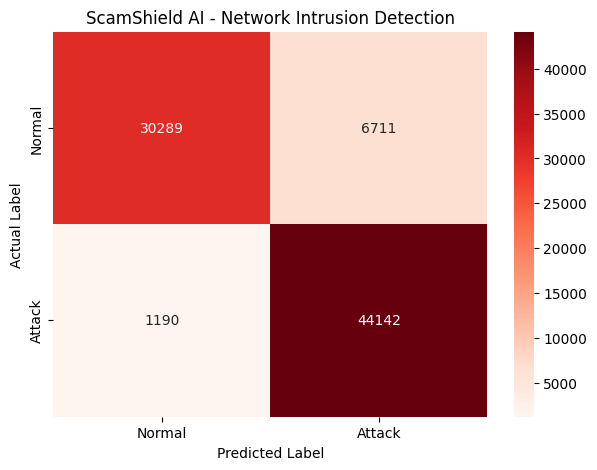

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("ScamShield AI - Network Intrusion Detection")

plt.show()

In [22]:
sample = X_test.iloc[[0]]

prediction = network_model.predict(sample)[0]

probabilities = network_model.predict_proba(sample)[0]

attack_index = list(network_model.classes_).index(1)

attack_probability = probabilities[attack_index]

print("NETWORK TRAFFIC ANALYSIS")
print("------------------------")

if prediction == 1:
    print("WARNING: ATTACK TRAFFIC DETECTED")
else:
    print("NORMAL NETWORK TRAFFIC")

print(
    "Model attack probability:",
    round(attack_probability * 100, 2),
    "%"
)

NETWORK TRAFFIC ANALYSIS
------------------------
Model attack probability: 75.48 %


In [23]:
import joblib

joblib.dump(
    network_model,
    "scamshield_network_model.pkl"
)

print("Network model saved successfully!")

Network model saved successfully!
